# Задача 6: Нелінійні регресії в Python

Нелінійна регресія пропонує гнучку техніку для моделювання складних взаємозв'язків. Ми хочемо пояснити ціну продажу SalePrice за допомогою року побудови YearBuilt. Для цієї мети використовуйте лише перші 500 спостережень з нашого DataFrame.

***Answer***

[Умова](../input/assignment_3.pdf). Дані ті самі, що й у задачі 5: повна версія Ames Housing ([De Cock, 2011](https://jse.amstat.org/v19n3/decock/AmesHousing.txt)), файл [`AmesHousing.txt`](../input/AmesHousing.txt) з 2930 продажами та 82 колонками, опис — [DataDocumentation.txt](../input/DataDocumentation.txt). Читаємо з `keep_default_na=False, na_values=[""]`, назви колонок зводимо до вигляду з умови (`Year Built` → `YearBuilt`).

За умовою беремо перші 500 рядків: `df.iloc[:500]`. Пропусків у `YearBuilt` і `SalePrice` немає.

**Важливо:** рядки файлу впорядковано за роком продажу. Тому перші 500 рядків — це лише продажі 2009 (159) і 2010 (341) років, а не випадкова вибірка. Висновки стосуються саме цих продажів.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display

TASK_DIR = Path.cwd()
if (TASK_DIR / "labs" / "task3").is_dir():
    TASK_DIR = TASK_DIR / "labs" / "task3"
elif TASK_DIR.name == "notebooks":
    TASK_DIR = TASK_DIR.parent
INPUT_DIR = TASK_DIR / "input"
FIGURES_DIR = TASK_DIR / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

SEED = 42
ALPHA = 0.05
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})
pd.set_option("display.float_format", "{:.6g}".format)


In [2]:
DATA_PATH = INPUT_DIR / "AmesHousing.txt"
df = pd.read_csv(DATA_PATH, sep="\t", keep_default_na=False, na_values=[""])
# Назви як у Kaggle та в умові: "Year Built" -> "YearBuilt".
df.columns = df.columns.str.replace(" ", "").str.replace("/", "")
for column in df.select_dtypes(exclude="number").columns:
    df[column] = df[column].str.strip()
print("Розмір df:", df.shape)
display(df[["YearBuilt", "SalePrice"]].isna().sum().to_frame("Пропуски"))


Розмір df: (2930, 82)


,Пропуски
YearBuilt,0
SalePrice,0


In [3]:
from scipy.optimize import curve_fit

df_500 = df.iloc[:500].copy()
x = df_500["YearBuilt"].to_numpy(dtype=float)
y = df_500["SalePrice"].to_numpy(dtype=float)
n = len(y)
display(df_500[["YearBuilt", "SalePrice"]].describe().T)
print("Роки продажу в перших 500 рядках:", df_500["YrSold"].value_counts().sort_index().to_dict())
print("Роки продажу в усьому наборі:", df["YrSold"].value_counts().sort_index().to_dict())


,count,mean,std,min,25%,50%,75%,max
YearBuilt,500,1977.2,28.2123,1875,1961,1978,2003,2010
SalePrice,500,191554,89450.5,12789,134950,171750,222875,611657


Роки продажу в перших 500 рядках: {2009: 159, 2010: 341}
Роки продажу в усьому наборі: {2006: 625, 2007: 694, 2008: 622, 2009: 648, 2010: 341}


## (а)

Побудуйте двовимірну діаграму розсіювання (bivariate scatter plot) та оцініть відповідну лінійну (!) модель через statsmodels або LinearRegression з sklearn. Додайте лінію регресії на графік.

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   -3.46e+06   2.28e+05    -15.149      0.000   -3.91e+06   -3.01e+06
YearBuilt   1846.6549    115.494     15.989      0.000    1619.740    2073.570


,Лінійна модель
beta_0,-3.45966e+06
beta_1 (YearBuilt),1846.65
SE(beta_1),115.494
t,15.9893
p,9.55339e-47
R²,0.339221
Найстаріший рік,1875
Його фактична ціна,94000
Його прогноз,2818.23


,Продажів,"Середній залишок, дол.",Частка точок під прямою
YearBuilt,,,
"(1870, 1950]",79,22519.3,0.329114
"(1950, 1980]",185,-25041.8,0.8
"(1980, 2000]",93,-4279.42,0.645161
"(2000, 2010]",143,22739.1,0.524476


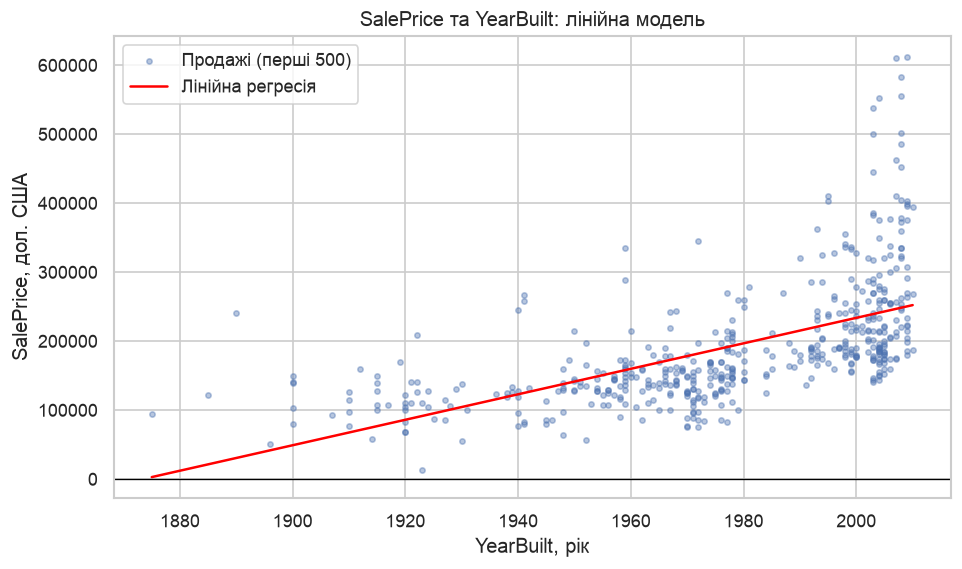

In [4]:
# Виберіть df.iloc[:500].copy(); побудуйте графік та лінійну модель.
# ========= YOUR CODE STARTS HERE ========= #

linear_model = smf.ols("SalePrice ~ YearBuilt", data=df_500).fit()
print(linear_model.summary().tables[1])
linear_pred = linear_model.fittedvalues.to_numpy()
display(pd.Series({"beta_0": linear_model.params["Intercept"], "beta_1 (YearBuilt)": linear_model.params["YearBuilt"],
                   "SE(beta_1)": linear_model.bse["YearBuilt"], "t": linear_model.tvalues["YearBuilt"],
                   "p": linear_model.pvalues["YearBuilt"], "R²": linear_model.rsquared,
                   "Найстаріший рік": x.min(), "Його фактична ціна": y[x.argmin()],
                   "Його прогноз": linear_pred[x.argmin()]}).to_frame("Лінійна модель"))

# Чи є систематичний візерунок залишків уздовж років?
year_groups = pd.cut(df_500["YearBuilt"], [1870, 1950, 1980, 2000, 2010])
display(pd.DataFrame({"Продажів": linear_model.resid.groupby(year_groups, observed=True).size(),
                      "Середній залишок, дол.": linear_model.resid.groupby(year_groups, observed=True).mean(),
                      "Частка точок під прямою": (linear_model.resid < 0).groupby(year_groups, observed=True).mean()}))

years = np.linspace(x.min(), x.max(), 300)
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(x, y, s=10, alpha=0.4, label="Продажі (перші 500)")
ax.plot(years, linear_model.params["Intercept"] + linear_model.params["YearBuilt"] * years,
        color="red", label="Лінійна регресія")
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="SalePrice та YearBuilt: лінійна модель", xlabel="YearBuilt, рік", ylabel="SalePrice, дол. США")
ax.legend()
fig.savefig(FIGURES_DIR / "problem6_linear.png")
plt.show()


***Answer***

Модель: $SalePrice_i=\beta_0+\beta_1 YearBuilt_i+\varepsilon_i$, оцінена МНК через `statsmodels`.

- $\widehat\beta_1=1846.65$ ($SE=115.5$, $t=15.99$, $p\approx10^{-46}$): будинок, збудований на рік пізніше, у середньому дорожчий на 1847 дол.
- $\widehat\beta_0=-3.46$ млн — це «ціна» будинку року 0. Економічного змісту вона не має: це продовження прямої далеко за межі даних.
- $R^2=0.339$: рік будівництва пояснює третину варіації цін.

**Що видно на графіку.** Хмара точок опукла: до 1950 р. ціни ростуть повільно, після 1990 р. — швидко. Пряма цього не враховує, тому залишки мають систематичний візерунок:
- до 1950 р. пряма занижує ціни (середній залишок +22.5 тис. дол.);
- у 1951–1980 рр. 80% точок лежать під прямою (середній залишок $-25$ тис.);
- після 2000 р. пряма знову занижує ціни (+22.7 тис.).

Для найстарішого будинку (1875 р.) пряма прогнозує лише 2818 дол., хоча його продано за 94000; продовжена вліво, вона дала б від'ємні ціни. Крім того, розкид цін для нових будинків значно більший. Усе це вказує, що лінійна форма тут не найкраща.

## (б)

Тепер оцініть відповідну нелінійну регресію (наприклад, експоненціальну або степеневу залежність) за допомогою функції curve_fit з бібліотеки scipy.optimize. Додайте криву регресії на графік і порівняйте (кількісно) якість підгонки нелінійної моделі з лінійною за допомогою метрик $R^2$ та MSE.

,Початкове значення p0,Оцінка curve_fit
a,161996,163627
b,0.0101651,0.0129343


Річне зростання прогнозу: 100*(exp(b) - 1) = 1.302%


,Параметрів,R²,"MSE, дол.²","RMSE, дол."
Лінійна,2,0.339221,5.27658e+09,72640.1
Експоненційна,2,0.392684,4.84965e+09,69639.5


,"Лінійна, дол.","Експоненційна, дол."
YearBuilt,,
1880,12051.5,51085.3
1920,85917.7,85701.6
1960,159784,143774
2000,233650,241198
2010,252117,274503


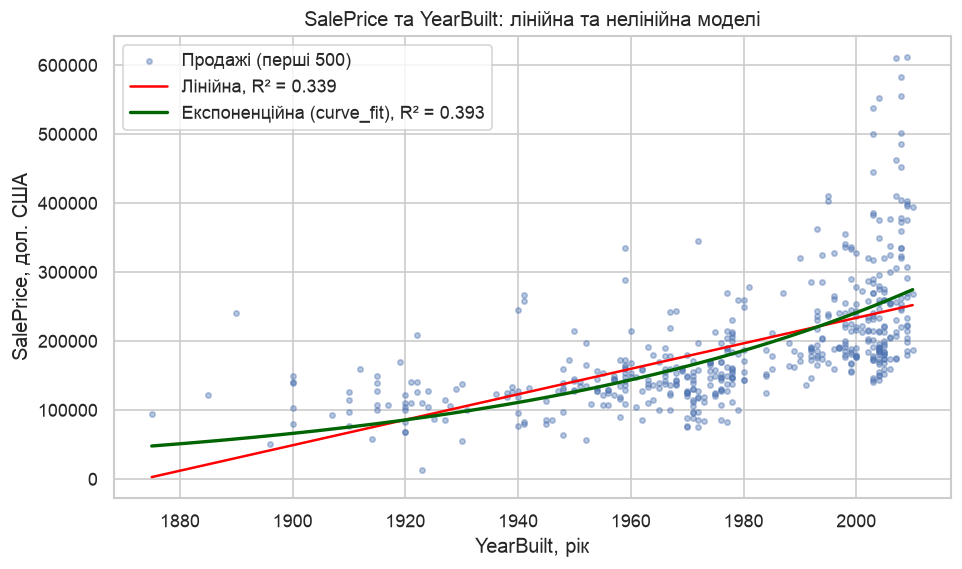

In [5]:
# Визначте нелінійну функцію; застосуйте curve_fit та порівняйте R² і MSE.
# ========= YOUR CODE STARTS HERE ========= #

YEAR_0 = 1970  # опорний рік: a - прогноз ціни будинку, збудованого в 1970 р.


def exponential(year, a, b):
    """SalePrice = a * exp(b * (YearBuilt - 1970))."""
    return a * np.exp(b * (year - YEAR_0))


# Початкові значення: якщо log(SalePrice) = log(a) + b * (YearBuilt - 1970),
# то їх дає звичайна лінійна регресія логарифма ціни.
log_fit = sm.OLS(np.log(y), sm.add_constant(x - YEAR_0)).fit()
p0 = [np.exp(log_fit.params[0]), log_fit.params[1]]
params, pcov = curve_fit(exponential, x, y, p0=p0)
a_hat, b_hat = params
exp_pred = exponential(x, a_hat, b_hat)
display(pd.DataFrame({"Початкове значення p0": p0, "Оцінка curve_fit": params}, index=["a", "b"]))
print(f"Річне зростання прогнозу: 100*(exp(b) - 1) = {100 * np.expm1(b_hat):.3f}%")


def r_squared(prediction):
    return 1 - np.sum((y - prediction) ** 2) / np.sum((y - y.mean()) ** 2)


def mse(prediction):
    return np.mean((y - prediction) ** 2)


assert np.isclose(r_squared(linear_pred), linear_model.rsquared)
display(pd.DataFrame({
    "Параметрів": [2, 2],
    "R²": [r_squared(linear_pred), r_squared(exp_pred)],
    "MSE, дол.²": [mse(linear_pred), mse(exp_pred)],
    "RMSE, дол.": [np.sqrt(mse(linear_pred)), np.sqrt(mse(exp_pred))],
}, index=["Лінійна", "Експоненційна"]))

check_years = np.array([1880, 1920, 1960, 2000, 2010])
display(pd.DataFrame({
    "Лінійна, дол.": linear_model.params["Intercept"] + linear_model.params["YearBuilt"] * check_years,
    "Експоненційна, дол.": exponential(check_years, a_hat, b_hat),
}, index=pd.Index(check_years, name="YearBuilt")))

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(x, y, s=10, alpha=0.4, label="Продажі (перші 500)")
ax.plot(years, linear_model.params["Intercept"] + linear_model.params["YearBuilt"] * years,
        color="red", label=f"Лінійна, R² = {r_squared(linear_pred):.3f}")
ax.plot(years, exponential(years, a_hat, b_hat), color="darkgreen", linewidth=2,
        label=f"Експоненційна (curve_fit), R² = {r_squared(exp_pred):.3f}")
ax.set(title="SalePrice та YearBuilt: лінійна та нелінійна моделі", xlabel="YearBuilt, рік",
       ylabel="SalePrice, дол. США")
ax.legend()
fig.savefig(FIGURES_DIR / "problem6_nonlinear.png")
plt.show()


***Answer***

**Модель:**
$$SalePrice_i=a\,e^{\,b\,(YearBuilt_i-1970)}+\varepsilon_i.$$
Чому експонента: вона описує зростання ціни на сталий **відсоток** за кожен пізніший рік будівництва, має опуклу форму, як хмара точок, і завжди дає додатні ціни. Рік зсунуто на 1970 (близько до середнього 1977): тоді $a$ — прогноз ціни будинку 1970 р., а обчислення стабільніші (пункт г).

`curve_fit` мінімізує
$$RSS(a,b)=\sum_i\big(y_i-a\,e^{\,b(x_i-1970)}\big)^2$$
ітераційно (за замовчуванням методом Левенберга–Марквардта), починаючи з початкових значень `p0`. Явної формули, як у лінійній регресії, немає. `p0` взято з лінійної регресії $\log(SalePrice)$ на $(YearBuilt-1970)$: $a_0=161996$, $b_0=0.0102$.

**Оцінки:** $\widehat a=163627$ дол. (прогноз для будинку 1970 р.), $\widehat b=0.01293$. Кожен пізніший рік будівництва збільшує прогноз на $100(e^{\widehat b}-1)=1.30\%$. Оцінка $\widehat b$ більша за початкову $0.0102$. NLS мінімізує квадрати помилок **у доларах**, тож дорогі нові будинки з великими відхиленнями важать більше; регресія логарифма мінімізує відносні помилки.

**Порівняння на тих самих 500 продажах** (обидві моделі мають по 2 параметри, тож скоригований $R^2$ не потрібен):

| Модель | $R^2$ | MSE, дол.² | RMSE, дол. |
|---|---|---|---|
| Лінійна | 0.339 | $5.277\cdot10^9$ | 72640 |
| Експоненційна | 0.393 | $4.850\cdot10^9$ | 69640 |

$$R^2=1-\frac{\sum_i(y_i-\widehat y_i)^2}{\sum_i(y_i-\bar y)^2},\qquad MSE=\frac1n\sum_i(y_i-\widehat y_i)^2.$$

Експоненційна модель краща: MSE менша на 8.1%, $R^2$ вищий на 0.053. Крива краще передає повільне зростання цін старих будинків і швидке — нових. Для будинку 1880 р. вона прогнозує 51 тис. дол. замість 12 тис. у прямої, для 2010 р. — 275 тис. замість 252 тис.

Проте покращення помірне: обидві моделі пояснюють менше 40% варіації, бо ціну визначають також площа, якість, район тощо. Для нелінійної моделі $R^2$ — лише описова міра: розклад $TSS=ESS+RSS$ тут не виконується, і $R^2$ навіть може бути від'ємним. Порівнювати $R^2$ двох моделей тут коректно, бо вони мають ті самі $y$ і $n$; це рівнозначно порівнянню MSE.

## (в)

Поясніть своїми словами, чому всі класичні тести та статистичні висновки (наприклад, точні t-розподіли для малих вибірок) не є прямо застосовними до оцінок нелінійного методу найменших квадратів (NLS), отриманих через curve_fit.

,Оцінка,SE з pcov (наближена),Оцінка / SE,Наближений 95% ДІ: від,до
a,163627,3854.67,42.449,156072,171182
b,0.0129343,0.000813133,15.9068,0.0113406,0.0145281


Кореляція оцінок a і b: -0.748
Jarque-Bera для залишків NLS: JB = 672.3, p = 1.04e-146


,"Стандартне відхилення залишків, дол."
"(1870, 1950]",46474.6
"(1950, 1980]",43587
"(1980, 2000]",60448
"(2000, 2010]",102347


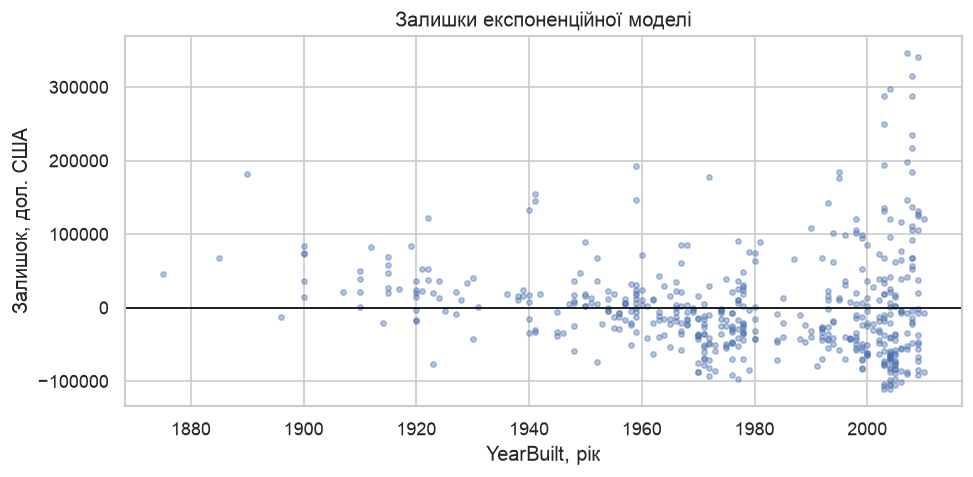

In [6]:
# За потреби додайте допоміжні обчислення для пояснення.
# ========= YOUR CODE STARTS HERE ========= #

# curve_fit оцінює коваріацію через лінеаризацію: pcov = s^2 (J^T J)^(-1),
# де J - похідні моделі за a і b в точці оцінки, s^2 = RSS / (n - 2).
t = x - YEAR_0
J = np.column_stack([np.exp(b_hat * t), a_hat * t * np.exp(b_hat * t)])
s2 = np.sum((y - exp_pred) ** 2) / (n - 2)
assert np.allclose(s2 * np.linalg.inv(J.T @ J), pcov, rtol=1e-4)
se = np.sqrt(np.diag(pcov))
z = stats.norm.ppf(1 - ALPHA / 2)
display(pd.DataFrame({"Оцінка": params, "SE з pcov (наближена)": se, "Оцінка / SE": params / se,
                      "Наближений 95% ДІ: від": params - z * se, "до": params + z * se}, index=["a", "b"]))
print(f"Кореляція оцінок a і b: {pcov[0, 1] / (se[0] * se[1]):.3f}")

residuals = y - exp_pred
jb = stats.jarque_bera(residuals)
print(f"Jarque-Bera для залишків NLS: JB = {jb.statistic:.1f}, p = {jb.pvalue:.3g}")
spread = pd.Series(residuals).groupby(pd.cut(x, [1870, 1950, 1980, 2000, 2010])).std()
display(spread.to_frame("Стандартне відхилення залишків, дол."))

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(x, residuals, s=10, alpha=0.4)
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Залишки експоненційної моделі", xlabel="YearBuilt, рік", ylabel="Залишок, дол. США")
fig.savefig(FIGURES_DIR / "problem6_residuals.png")
plt.show()


***Answer***

**Чому в лінійній регресії висновки точні.** За фіксованих $X$ оцінка
$$\widehat\beta=(X^TX)^{-1}X^Ty$$
є **лінійною функцією** $y$. Якщо похибки нормальні, $\varepsilon\sim N(0,\sigma^2I)$, то $\widehat\beta$ точно нормальна, а $(n-k)s^2/\sigma^2\sim\chi^2(n-k)$ і не залежить від $\widehat\beta$. Тому $t=(\widehat\beta_j-\beta_j)/SE(\widehat\beta_j)$ має **точний** t-розподіл для будь-якого $n$, навіть $n=10$. Так само точні й F-тести.

**Чому для NLS це не так.** Оцінка $\widehat\theta=(\widehat a,\widehat b)$ не має формули: її знаходить ітераційний алгоритм, і вона є **нелінійною** функцією $y$. Навіть із нормальними похибками $\widehat\theta$ не є точно нормальною, у малих вибірках може бути зміщеною, а $s^2$ не має точного розподілу $\chi^2$. Отже, точних t- і F-розподілів немає.

**Що дає `curve_fit`.** Матриця `pcov` обчислюється через **лінеаризацію**: біля $\widehat\theta$ модель замінюють лінійною з «регресорами»-похідними $J=\big[\partial f/\partial a,\ \partial f/\partial b\big]=\big[e^{bt},\ a\,t\,e^{bt}\big]$:
$$\widehat{Cov}(\widehat\theta)\approx s^2(J^TJ)^{-1},\qquad s^2=\frac{RSS}{n-2}.$$
Ми перевірили цю формулу (`assert`). Це **асимптотичне наближення**: воно добре, коли $n$ велике, а модель майже лінійна в межах невизначеності параметрів. Звідси $SE(\widehat a)=3855$, $SE(\widehat b)=0.00081$ і наближений 95% інтервал для $b$: $[0.0113;\ 0.0145]$, тобто 1.14–1.46% на рік. Тут ми свідомо беремо нормальний квантиль 1.96, а не точний t-квантиль. Самих p-значень `curve_fit` не дає.

Наближення ще й залежить від того, як записано модель. У пункті (г) та сама крива, записана як $a\,e^{by}$ без зсуву року, має відносну похибку $SE(\widehat a)/\widehat a=162\%$ замість 2.4%.

**Наші дані додатково порушують припущення:**
- залишки ненормальні: Jarque–Bera $=672$, $p\approx10^{-146}$;
- розкид залишків зростає з роком: стандартне відхилення близько 44–46 тис. дол. до 1980 р., 60 тис. у 1981–2000 рр. і 102 тис. після 2000 р. (графік). Формула `pcov` припускає однакову дисперсію;
- перші 500 рядків не є випадковою вибіркою.

Тому навіть наближені стандартні похибки й інтервали слід сприймати обережно.

## (г)

Які проблеми з обчислювальною збіжністю (convergence) та перенавчанням можуть виникнути, якщо ми вирішимо побудувати складну нелінійну регресію, використовуючи одночасно всі наявні пояснювальні змінні у датасеті?

In [7]:
# За потреби додайте допоміжні обчислення для пояснення.
# ========= YOUR CODE STARTS HERE ========= #

# 1) Збіжність: та сама крива, але без зсуву року.
def exponential_raw(year, a, b):
    return a * np.exp(b * year)


with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    raw_default, raw_default_cov = curve_fit(exponential_raw, x, y)  # p0 = [1, 1] за замовчуванням
    with np.errstate(over="ignore"):
        raw_default_mse = mse(exponential_raw(x, *raw_default))
print("Без p0 curve_fit повернув:", raw_default, "| MSE:", raw_default_mse)
print("Попередження:", sorted({f"{w.category.__name__}: {w.message}" for w in caught}))

raw_params, raw_cov = curve_fit(exponential_raw, x, y, p0=[p0[0] * np.exp(-p0[1] * YEAR_0), p0[1]])
raw_se = np.sqrt(np.diag(raw_cov))
display(pd.DataFrame({
    "a": [a_hat, raw_params[0]], "SE(a) / a": [se[0] / a_hat, raw_se[0] / raw_params[0]],
    "b": [b_hat, raw_params[1]], "Кореляція a і b": [pcov[0, 1] / se.prod(), raw_cov[0, 1] / raw_se.prod()],
    "MSE": [mse(exp_pred), mse(exponential_raw(x, *raw_params))],
}, index=["a*exp(b*(year - 1970))", "a*exp(b*year), добре p0"]))

# 2) Усі пояснювальні змінні перших 500 рядків: кількість параметрів проти n.
features = df_500.drop(columns=["Order", "PID", "SalePrice"])
categorical = ["MSSubClass"] + list(features.select_dtypes(exclude="number").columns)
X_all = pd.get_dummies(features, columns=categorical, drop_first=True, dtype=float)
complete = X_all.notna().all(axis=1)
X_complete = X_all[complete]
display(pd.Series({
    "Рядків": n,
    "Стовпців після кодування категорій": X_all.shape[1],
    "Повних рядків (без NaN)": complete.sum(),
    "Стовпців, що в повних рядках завжди 0": (X_complete != 0).sum().eq(0).sum(),
    "Стовпців, ненульових лише в 1 рядку": (X_complete != 0).sum().eq(1).sum(),
    "Ранг [1, X] на повних рядках": np.linalg.matrix_rank(np.column_stack([np.ones(len(X_complete)), X_complete])),
}).to_frame("Значення"))


Без p0 curve_fit повернув: [1. 1.] | MSE: inf
Попередження: ['OptimizeWarning: Covariance of the parameters could not be estimated', 'RuntimeWarning: overflow encountered in exp']


,a,SE(a) / a,b,Кореляція a і b,MSE
a*exp(b*(year - 1970)),163627,0.0235577,0.0129343,-0.74794,4.84965e+09
"a*exp(b*year), добре p0",1.40509e-06,1.6199,0.0129344,-0.999953,4.84965e+09


,Значення
Рядків,500
Стовпців після кодування категорій,234
Повних рядків (без NaN),393
"Стовпців, що в повних рядках завжди 0",16
"Стовпців, ненульових лише в 1 рядку",19
"Ранг [1, X] на повних рядках",204


***Answer***

**Проблеми зі збіжністю.**
- NLS не має явного розв'язку: алгоритм рухається від `p0` до мінімуму $RSS(\theta)$. Ця функція може мати кілька локальних мінімумів і пласкі «долини». Алгоритм може зупинитися не там, розійтися або сильно залежати від `p0`. З усіма змінними параметрів сотні, і кожен крок потребує матриці похідних $J$ розміру $n\times p$. Знайти добрі початкові значення для всіх параметрів практично неможливо.
- **Навіть одна змінна показує проблему.** Ту саму експоненту без зсуву року, $a\,e^{b\cdot YearBuilt}$, запустили зі стандартним `p0 = [1, 1]`. Тоді $e^{1\cdot2000}$ переповнюється, і `curve_fit` повернув $[1,1]$ без змін, з MSE $=\infty$ — лише з попередженнями, **без помилки**. З добрим `p0` ця версія знаходить ту саму криву (MSE однакова, $4.85\cdot10^9$). Але $\widehat a=1.4\cdot10^{-6}$, відносна похибка $\widehat a$ — 162%, а кореляція $\widehat a$ і $\widehat b$ — $-0.99995$: параметри майже неможливо розділити, задача погано обумовлена. Зі зсувом на 1970 кореляція $-0.75$, а відносна похибка — 2.4%. Змінні Ames мають дуже різні масштаби (площі ~$10^4$, роки ~2000, індикатори 0/1), тож таких проблем стане значно більше. Потрібні центрування й масштабування, обмеження на параметри, розумні `p0`.
- **Не всі параметри можна оцінити.** Для перших 500 рядків кодування всіх змінних дає 234 стовпці. `curve_fit` не приймає `NaN`, а повних рядків лише 393. У цих рядках 16 індикаторів завжди дорівнюють 0, а 19 ненульові лише в одному рядку. Ранг матриці $[1, X]$ — 204 замість 235, тобто навіть **лінійна** модель не має єдиного розв'язку. Для нелінійної моделі $J^TJ$ вироджена: `pcov` стає нескінченною, а алгоритм блукає напрямками, де RSS не змінюється.

**Перенавчання.**
- Параметрів стає стільки ж, скільки спостережень (235 і більше на 393 рядки), а нелінійні форми додають ще гнучкості. Така модель підганяє шум: навчальний $R^2$ буде близький до 1, а прогнози для нових будинків — погані.
- У задачі 5 це виміряно навіть для лінійної моделі на 2414 рядках: модель із 269 параметрами мала навчальну MSE $4.18\cdot10^8$, а MSE за LeaveOneOut — $9.56\cdot10^8$. Модель із 91 параметром прогнозувала краще. Рідкісні категорії давали параметри, підігнані під один будинок ($h=1$). Тут $n$ у п'ять разів менше, тож ризик ще вищий.

**Що робити:** обирати небагато змінних (відбір, як у задачі 5) і прості форми, підказані графіками; часто достатньо лінійної моделі для $\log(SalePrice)$. Також допомагає регуляризація, а якість варто перевіряти крос-валідацією, а не навчальним $R^2$.